# Random Forest — Product Classification

Part of the project's model-comparison phase. Like the Naive Bayes, Logistic Regression and Linear SVM
baselines, this notebook predicts the **Product** (11 classes) of a CFPB complaint from its cleaned narrative,
using the shared train/test split and macro-F1 as the headline metric.

A random forest averages many decision trees, each grown on a bootstrap sample of the training data and
restricted to a random subset of features at every split. Averaging decorrelated trees reduces the variance of
a single deep tree and lets the model capture non-linear interactions between features.

In [1]:
import gc
import hashlib
import json
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.ensemble import RandomForestClassifier

In [2]:
RANDOM_STATE = 42
MODEL_KEY = "random_forest"
DISPLAY_NAME = "Random Forest"
FEATURES_LABEL = "TF-IDF → SVD-300"
N_JOBS = 4             # RAM is limited: never more than 4 parallel workers
TUNE_SAMPLES = 30_000  # size of the stratified training subsample used for grid search

DATA_PATH = Path("../../data/processed/complaint_router_modeling_data.csv")
FEATURE_CACHE_PATH = Path("../../data/processed/svd300_features.npz")
FIGURES_DIR = Path("../../figures")
METRICS_DIR = Path("../../results/metrics")

SHORT_LABELS = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt/Credit Mgmt",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/Personal Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan",
}

## 1. Load Data

The processed dataset already carries the shared 80/20 `split` column (stratified on Product, seed 42),
so every model in the project is trained and tested on exactly the same complaints. Only the four
columns needed here are loaded.

In [3]:
# keep_default_na=False: a narrative such as "null" stays text instead of becoming NaN
df = pd.read_csv(
    DATA_PATH,
    usecols=["Complaint ID", "Product", "clean_narrative", "split"],
    keep_default_na=False,
)

train = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
del df

y_train = train["Product"].to_numpy()
y_test = test["Product"].to_numpy()

print(f"Training samples: {len(train):,}")
print(f"Testing samples: {len(test):,}")
print("Number of classes:", train["Product"].nunique())
print("Empty clean narratives:", int((train["clean_narrative"] == "").sum() + (test["clean_narrative"] == "").sum()))

Training samples: 130,000
Testing samples: 32,500
Number of classes: 11
Empty clean narratives: 0


## 2. Features: TF-IDF → Truncated SVD (300 components)

The linear baselines (Naive Bayes, Logistic Regression, Linear SVM) train directly on the sparse
100,000-dimensional TF-IDF matrix. That is impractical for the models in this folder:
`HistGradientBoostingClassifier` needs a dense matrix (~130k × 100k float32 ≈ 52 GB), random forests and
k-NN accept sparse input but become very slow with 100k mostly-zero columns, and an MLP's first layer
would need 25M+ weights. We therefore compress TF-IDF with **truncated SVD (latent semantic analysis, LSA)**
into 300 dense dimensions that capture the main word co-occurrence patterns ("topics").

- TF-IDF uses the project's shared config (unigrams + bigrams, `min_df=5`, `max_df=0.9`, sublinear TF,
  top 100k terms). TF-IDF and SVD are **fit on the training split only**, then applied to the test split.
- SVD outputs are stored as `float32` to halve memory.
- The cost of this compression (some discriminative detail is lost) is measured in
  `03_dimensionality_reduction_clustering.ipynb`, which plots macro-F1 against the number of SVD components.
- All four notebooks in `notebooks/models/` use identical features, so the first one to run saves them to
  `data/processed/svd300_features.npz`. Later runs reuse the cache only if its Complaint IDs, labels, text
  fingerprint and TF-IDF/SVD settings match the current CSV; otherwise the features are recomputed.

In [4]:
TFIDF_PARAMS = dict(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9,
    sublinear_tf=True,
    max_features=100_000,
)
N_COMPONENTS = 300

# Describes exactly how the cached features were built
FEATURE_CONFIG = f"tfidf={sorted(TFIDF_PARAMS.items())} | svd={N_COMPONENTS} | seed={RANDOM_STATE}"


def data_fingerprint(frame):
    # One hash per row (ID + label + text), then a single SHA-256 over all row hashes
    row_hashes = pd.util.hash_pandas_object(
        frame[["Complaint ID", "Product", "clean_narrative"]], index=False
    ).to_numpy()
    return hashlib.sha256(row_hashes.tobytes()).hexdigest()


DATA_FINGERPRINT = data_fingerprint(train) + data_fingerprint(test)

In [5]:
def load_cached_features(path):
    # Returns (X_train, X_test, explained_variance) if the cache matches the current CSV, else None
    if not path.exists():
        print(f"No feature cache found at {path}")
        return None
    try:
        with np.load(path, allow_pickle=False) as cache:
            checks = {
                "feature config": str(cache["feature_config"]) == FEATURE_CONFIG,
                "train Complaint IDs": np.array_equal(cache["train_ids"], train["Complaint ID"].to_numpy()),
                "test Complaint IDs": np.array_equal(cache["test_ids"], test["Complaint ID"].to_numpy()),
                "train labels": np.array_equal(cache["y_train"], y_train.astype(str)),
                "test labels": np.array_equal(cache["y_test"], y_test.astype(str)),
                "text fingerprint": str(cache["data_fingerprint"]) == DATA_FINGERPRINT,
            }
            failed = [name for name, ok in checks.items() if not ok]
            if failed:
                print("Feature cache does not match the current data (" + ", ".join(failed) + ")")
                return None
            return cache["X_train"], cache["X_test"], float(cache["explained_variance"])
    except Exception as exc:  # unreadable or old-format cache: just rebuild it
        print(f"Could not read feature cache ({exc!r})")
        return None


def compute_features():
    vectorizer = TfidfVectorizer(**TFIDF_PARAMS)
    X_train_tfidf = vectorizer.fit_transform(train["clean_narrative"])  # fit on train only
    X_test_tfidf = vectorizer.transform(test["clean_narrative"])
    print(f"TF-IDF shape (train): {X_train_tfidf.shape}")

    svd = TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
    X_train_svd = svd.fit_transform(X_train_tfidf).astype(np.float32)  # fit on train only
    X_test_svd = svd.transform(X_test_tfidf).astype(np.float32)
    return X_train_svd, X_test_svd, float(svd.explained_variance_ratio_.sum())


def save_feature_cache(path, X_train_svd, X_test_svd, explained_variance):
    path.parent.mkdir(parents=True, exist_ok=True)
    # Write to a temporary file and rename it, so another notebook never reads a half-written cache
    tmp_path = path.with_name(f"{path.stem}.{os.getpid()}.tmp.npz")
    np.savez(
        tmp_path,
        X_train=X_train_svd,
        X_test=X_test_svd,
        y_train=y_train.astype(str),
        y_test=y_test.astype(str),
        train_ids=train["Complaint ID"].to_numpy(),
        test_ids=test["Complaint ID"].to_numpy(),
        explained_variance=np.float64(explained_variance),
        feature_config=np.array(FEATURE_CONFIG),
        data_fingerprint=np.array(DATA_FINGERPRINT),
    )
    try:
        os.replace(tmp_path, path)
        print(f"Saved feature cache to {path} ({path.stat().st_size / 1e6:,.0f} MB)")
    except OSError as exc:  # e.g. another notebook is reading the cache right now
        tmp_path.unlink(missing_ok=True)
        print(f"Could not save feature cache ({exc!r}); continuing without it")

In [6]:
start = time.perf_counter()

cached = load_cached_features(FEATURE_CACHE_PATH)
if cached is not None:
    X_train, X_test, svd_explained = cached
    print("Loaded cached SVD features")
else:
    print("Computing TF-IDF + SVD features (a few minutes)...")
    X_train, X_test, svd_explained = compute_features()
    save_feature_cache(FEATURE_CACHE_PATH, X_train, X_test, svd_explained)

feature_seconds = time.perf_counter() - start

# The narrative text is no longer needed; free it
del cached, train, test
gc.collect()

print(f"Feature time: {feature_seconds:.1f}s")
print(f"X_train: {X_train.shape}, dtype={X_train.dtype}")
print(f"X_test:  {X_test.shape}, dtype={X_test.dtype}")
print(f"Share of TF-IDF variance kept by {N_COMPONENTS} components: {svd_explained:.1%}")

Loaded cached SVD features
Feature time: 0.1s
X_train: (130000, 300), dtype=float32
X_test:  (32500, 300), dtype=float32
Share of TF-IDF variance kept by 300 components: 19.6%


## 3. Hyperparameter Tuning

- `max_depth` ∈ {None, 30} and `min_samples_leaf` ∈ {1, 3} control how far each tree grows.
- `max_features="sqrt"`: each split considers √300 ≈ 17 random SVD components.
- `class_weight="balanced_subsample"` re-weights the classes inside every bootstrap sample so that small
  products count as much as large ones (the project's class-imbalance strategy).
- The grid uses **150 trees** to halve tuning time (more trees mainly reduce variance and rarely change which
  depth/leaf setting wins); the final model uses **300 trees**.
- While tuning, each forest runs on one core and `GridSearchCV` runs 4 fits in parallel, to avoid 4 × 4
  competing worker processes; the final forest uses `n_jobs=4`.

### Tuning Subsample

Grid search runs on a **stratified 30,000-complaint subsample** of the training set, with 3-fold stratified
cross-validation and macro-F1 scoring. This keeps the search affordable for the slower models; the best
setting is then refit on the full training set and evaluated once on the test set.

Note: TF-IDF and SVD were fit on the full training set before cross-validation, so each validation fold's
(unlabeled) text slightly influenced the IDF weights and SVD basis. This leak is label-free and negligible.

In [7]:
tune_idx, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=TUNE_SAMPLES,
    stratify=y_train,
    random_state=RANDOM_STATE,
)
X_tune, y_tune = X_train[tune_idx], y_train[tune_idx]

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

print(f"Tuning samples: {len(y_tune):,} of {len(y_train):,} training complaints")
print(pd.Series(y_tune).map(SHORT_LABELS).value_counts().to_string())

Tuning samples: 30,000 of 130,000 training complaints
Credit Reporting        6462
Debt Collection         4616
Credit Card             3692
Checking/Savings        3692
Money Transfer          2769
Mortgage                1846
Student Loan            1846
Vehicle Loan            1846
Payday/Personal Loan    1385
Prepaid Card             923
Debt/Credit Mgmt         923


In [8]:
estimator = RandomForestClassifier(
    n_estimators=150,  # tuning only; the final model uses 300 trees
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=1,  # GridSearchCV already runs N_JOBS fits in parallel
    random_state=RANDOM_STATE,
)

param_grid = {
    "max_depth": [None, 30],
    "min_samples_leaf": [1, 3],
}

In [9]:
search = GridSearchCV(
    estimator,
    param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=N_JOBS,
    refit=False,  # the best setting is refit on the full training set below
    verbose=1,
)

start = time.perf_counter()
search.fit(X_tune, y_tune)
tune_seconds = time.perf_counter() - start

best_params = search.best_params_
print(f"Tuning time: {tune_seconds / 60:.1f} min")
print("Best params:", best_params)
print(f"Best CV macro-F1 (30k subsample): {search.best_score_:.4f}")

Fitting 3 folds for each of 4 candidates, totalling 12 fits


Tuning time: 4.5 min
Best params: {'max_depth': 30, 'min_samples_leaf': 3}
Best CV macro-F1 (30k subsample): 0.6820


In [10]:
cv_results = pd.DataFrame(search.cv_results_)
cv_results = cv_results[
    [f"param_{name}" for name in param_grid]
    + ["mean_test_score", "std_test_score", "mean_fit_time", "rank_test_score"]
].sort_values("rank_test_score")
cv_results.columns = [col.removeprefix("param_").split("__")[-1] for col in cv_results.columns]
cv_results.round(4)

,max_depth,min_samples_leaf,mean_test_score,std_test_score,mean_fit_time,rank_test_score
3,30,3,0.6820,0.0019,103.3759,1
1,None,3,0.6809,0.0010,73.7128,2
0,None,1,0.6713,0.0022,79.5517,3
2,30,1,0.6707,0.0025,90.6358,4


## 4. Final Model on the Full Training Set

The best depth/leaf setting is refit on the full training set with 300 trees.

In [11]:
final_model = clone(estimator).set_params(**best_params, n_estimators=300, n_jobs=N_JOBS)

start = time.perf_counter()
final_model.fit(X_train, y_train)
train_seconds = time.perf_counter() - start

start = time.perf_counter()
y_pred = final_model.predict(X_test)
predict_seconds = time.perf_counter() - start

print(final_model)
print(f"Training time: {train_seconds:.1f}s ({len(y_train):,} complaints)")
print(f"Prediction time: {predict_seconds:.1f}s ({len(y_test):,} complaints)")

RandomForestClassifier(class_weight='balanced_subsample', max_depth=30,
                       min_samples_leaf=3, n_estimators=300, n_jobs=4,
                       random_state=42)
Training time: 354.0s (130,000 complaints)
Prediction time: 0.8s (32,500 complaints)


In [12]:
depths = [tree.get_depth() for tree in final_model.estimators_]
node_counts = [tree.tree_.node_count for tree in final_model.estimators_]

print(f"Trees: {len(final_model.estimators_)}")
print(f"Tree depth: mean {np.mean(depths):.1f}, max {np.max(depths)}")
print(f"Nodes per tree: mean {np.mean(node_counts):,.0f} (total {np.sum(node_counts):,})")

Trees: 300
Tree depth: mean 30.0, max 30
Nodes per tree: mean 26,778 (total 8,033,284)


### Which SVD Components Does the Forest Use?

Impurity-based importance of each of the 300 SVD components (component 1 has the largest singular value).
If importance is spread well beyond the first few components, the forest relies on fine-grained "topics" and
would likely benefit from keeping more SVD dimensions.

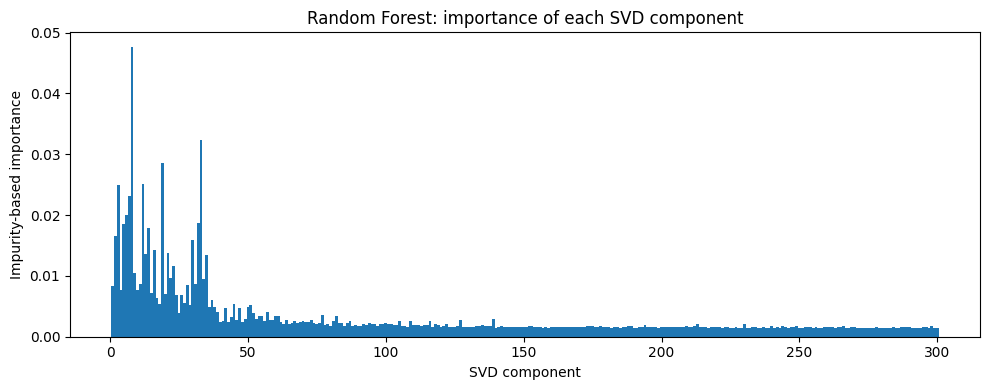

Importance share of the first 10 components: 18.5%
Importance share of the first 50 components: 54.8%
Importance share of the first 100 components: 67.3%


In [13]:
importances = final_model.feature_importances_

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(np.arange(1, len(importances) + 1), importances, width=1.0)
ax.set_xlabel("SVD component")
ax.set_ylabel("Impurity-based importance")
ax.set_title("Random Forest: importance of each SVD component")
plt.tight_layout()
plt.show()

for k in (10, 50, 100):
    print(f"Importance share of the first {k} components: {importances[:k].sum():.1%}")

In [14]:
# Fully grown forests can take several GB; predictions are stored, so free the model before evaluation
del final_model
gc.collect()

45

## 5. Test Set Evaluation

The held-out test set is used exactly once. Macro-F1 (the unweighted mean of per-product F1) is the
headline metric because it gives small products the same weight as large ones.

In [15]:
test_accuracy = accuracy_score(y_test, y_pred)
test_macro_f1 = f1_score(y_test, y_pred, average="macro")
test_weighted_f1 = f1_score(y_test, y_pred, average="weighted")

print(f"Test accuracy:    {test_accuracy:.4f}")
print(f"Test macro-F1:    {test_macro_f1:.4f}")
print(f"Test weighted-F1: {test_weighted_f1:.4f}")

Test accuracy:    0.7487
Test macro-F1:    0.7068
Test weighted-F1: 0.7431


In [16]:
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

                                                         precision    recall  f1-score   support

                            Checking or savings account      0.660     0.815     0.729      4000
                                            Credit card      0.691     0.752     0.721      4000
    Credit reporting or other personal consumer reports      0.761     0.856     0.806      7000
                                        Debt collection      0.745     0.722     0.734      5000
                              Debt or credit management      0.902     0.257     0.400      1000
     Money transfer, virtual currency, or money service      0.781     0.732     0.756      3000
                                               Mortgage      0.879     0.858     0.868      2000
Payday loan, title loan, personal loan, or advance loan      0.577     0.479     0.523      1500
                                           Prepaid card      0.878     0.482     0.622      1000
                             

### Confusion Matrix

Rows are normalized, so each row shows how the complaints of one actual product were distributed across
the predicted products (the diagonal is per-product recall).

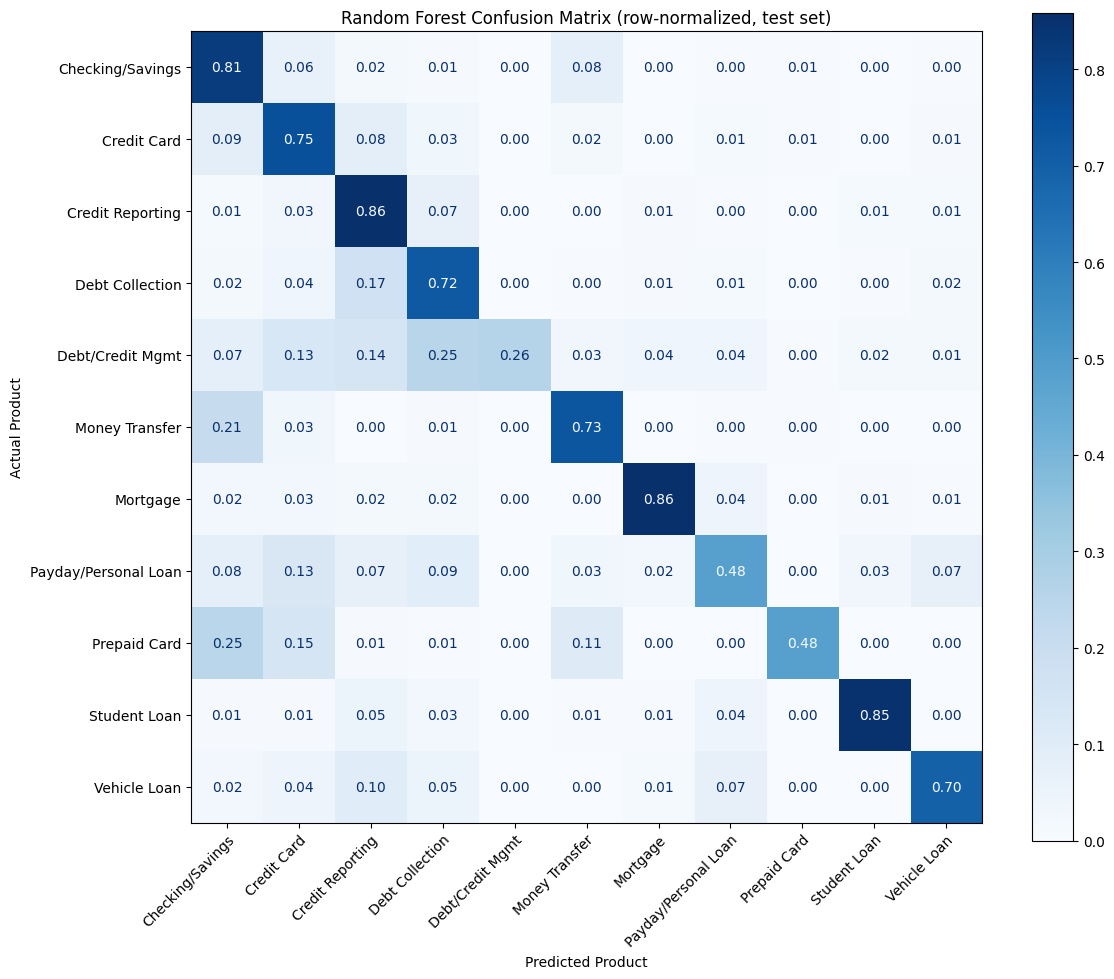

In [17]:
labels = sorted(SHORT_LABELS)

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    display_labels=[SHORT_LABELS[label] for label in labels],
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    ax=ax,
)
plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
ax.set_title(f"{DISPLAY_NAME} Confusion Matrix (row-normalized, test set)")
ax.set_xlabel("Predicted Product")
ax.set_ylabel("Actual Product")
plt.tight_layout()

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES_DIR / f"{MODEL_KEY}_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Save Metrics

Metrics are written to `results/metrics/<model>.json` in the same format as the baseline notebooks so that
`model_comparison.ipynb` can compare all models. Two extra fields are recorded here: `cv_n_samples` (the CV
score comes from the 30k tuning subsample, not the full training set) and `predict_seconds`.

In [18]:
def to_builtin(value):
    # Make parameter values JSON-friendly (tuples -> lists, numpy scalars -> Python)
    if isinstance(value, tuple):
        return [to_builtin(v) for v in value]
    if isinstance(value, np.generic):
        return value.item()
    return value


report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)

metrics = {
    "model": MODEL_KEY,
    "display_name": DISPLAY_NAME,
    "task": "product",
    "features": FEATURES_LABEL,
    "best_params": {name.split("__")[-1]: to_builtin(value) for name, value in best_params.items()},
    "cv_macro_f1": float(search.best_score_),
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "test_weighted_f1": float(test_weighted_f1),
    "per_class": {
        label: {
            "precision": float(report[label]["precision"]),
            "recall": float(report[label]["recall"]),
            "f1": float(report[label]["f1-score"]),
            "support": int(report[label]["support"]),
        }
        for label in labels
    },
    "train_seconds": float(train_seconds),
    "n_train": int(len(y_train)),
    "n_test": int(len(y_test)),
    "cv_n_samples": int(len(y_tune)),
    "predict_seconds": float(predict_seconds),
}

METRICS_DIR.mkdir(parents=True, exist_ok=True)
metrics_path = METRICS_DIR / f"{MODEL_KEY}.json"
metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print(f"Saved metrics to {metrics_path}")

Saved metrics to ..\..\results\metrics\random_forest.json


In [19]:
per_class_f1 = pd.Series(
    {SHORT_LABELS[label]: values["f1"] for label, values in metrics["per_class"].items()}
).sort_values(ascending=False)

print(f"{DISPLAY_NAME} ({FEATURES_LABEL})")
print(f"  Test macro-F1 {test_macro_f1:.3f} | accuracy {test_accuracy:.3f} | weighted-F1 {test_weighted_f1:.3f}")
print(f"  CV macro-F1 (30k subsample) {search.best_score_:.3f} | best params {metrics['best_params']}")
print(f"  Train {train_seconds:.0f}s | predict {predict_seconds:.0f}s | tuning {tune_seconds / 60:.1f} min")
print("\nPer-class F1 (best to worst):")
print(per_class_f1.round(3).to_string())

Random Forest (TF-IDF → SVD-300)
  Test macro-F1 0.707 | accuracy 0.749 | weighted-F1 0.743
  CV macro-F1 (30k subsample) 0.682 | best params {'max_depth': 30, 'min_samples_leaf': 3}
  Train 354s | predict 1s | tuning 4.5 min

Per-class F1 (best to worst):
Student Loan            0.871
Mortgage                0.868
Credit Reporting        0.806
Money Transfer          0.756
Vehicle Loan            0.745
Debt Collection         0.734
Checking/Savings        0.729
Credit Card             0.721
Prepaid Card            0.622
Payday/Personal Loan    0.523
Debt/Credit Mgmt        0.400


## Random Forest Results Summary

- **Best hyperparameters** (3-fold CV on the 30k subsample, 150 trees): `max_depth=30`, `min_samples_leaf=3`, CV macro-F1 **0.682**. Leaf size mattered more than the depth cap: `min_samples_leaf=3` beat 1 by about 0.01, while `max_depth=None` and 30 were essentially tied (0.681 vs 0.682). In the final 300-tree forest every tree reached the depth-30 cap (about 26.8k nodes per tree, 8.0M in total).
- **Test set:** macro-F1 **0.707**, accuracy **74.9%**, weighted-F1 **0.743**.
- **Strongest products:** Student Loan (F1 0.871), Mortgage (0.868) and Credit Reporting (0.806).
- **Weakest products:** Debt/Credit Management (0.400), Payday/Personal Loan (0.523) and Prepaid Card (0.622).
- **Effect of class weighting:** even with `class_weight="balanced_subsample"`, the small products are predicted conservatively, with very high precision but low recall. Debt/Credit Mgmt has precision 0.90 and recall 0.26, and Prepaid Card 0.88 and 0.48 (25% of Prepaid Card complaints are predicted as Checking/Savings). Gradient boosting's class weighting balanced precision and recall much more.
- **SVD components used:** importance is spread widely across the components. The first 10 hold only 18.5% of the total and the first 100 hold 67.3%, so the forest relies on many fine-grained LSA "topics" and might benefit from more SVD dimensions.
- **Timing:** the grid search took 4.5 min, the final 300-tree fit took **354 s (about 6 min)** on 4 cores, and prediction took 0.8 s. That makes it the slowest model to train here.
- **Compared with the other models:** the random forest is the weakest of the SVD-300 models (k-NN 0.709, gradient boosting 0.734, MLP 0.747). It is below Naive Bayes (0.723) and well below Logistic Regression on the full TF-IDF (0.776). See `model_comparison.ipynb` for the full table.